In [1]:
import random

ALPHABET = "ABCDEFGHIJKLMNOPQRSTUVWXYZ "  

rng = random.Random(17)
shuffled = list(ALPHABET)
rng.shuffle(shuffled)

encrypt_key = dict(zip(ALPHABET, shuffled))
decrypt_key = dict(zip(shuffled, ALPHABET))

def substitute(text, key):
    return "".join(key[char] for char in text)

message = "HELLO WORLD"
encrypted = substitute(message, encrypt_key)
recovered = substitute(encrypted, decrypt_key)

print("Original: ", repr(message))
print("Encrypted:", repr(encrypted))
print("Recovered:", repr(recovered))

assert recovered == message

Original:  'HELLO WORLD'
Encrypted: 'CBEEZQYZAEK'
Recovered: 'HELLO WORLD'


In [2]:
def count_reference_pairs(text):
    # One row per first character, one column per next character.
    counts = {first: {second: 1 for second in ALPHABET}
              for first in ALPHABET}

    for i in range(len(text) - 1):
        first = text[i]
        second = text[i + 1]
        counts[first][second] += 1

    return counts


counts = count_reference_pairs("THAT")
print("TH:", counts["T"]["H"])
print("HT:", counts["H"]["T"])

TH: 2
HT: 1


In [3]:
def build_probabilities(counts):
    probabilities = {}

    for first in ALPHABET:
        row = counts[first]
        row_total = sum(row.values())
        probabilities[first] = {}

        for second in ALPHABET:
            probabilities[first][second] = row[second] / row_total

    return probabilities


probabilities = build_probabilities(counts)
print(f"Chance of H after T: {probabilities['T']['H']:.2%}")

Chance of H after T: 7.14%


In [4]:
import math

def score_text(text, log_probs):
    score = 0.0
    for i in range(len(text) - 1):
        first = text[i]
        second = text[i + 1]
        score += log_probs[first][second]
    return score

# Convert each probability to a log once, so guesses can reuse the table.
log_probs = {
    first: {second: math.log(p) for second, p in row.items()}
    for first, row in probabilities.items()
}

print(f"THAT: {score_text('THAT', log_probs):.2f}")
print(f"TTAH: {score_text('TTAH', log_probs):.2f}")

THAT: -7.92
TTAH: -10.00


In [5]:
raw_passage = """
When the last train pulled out of the station the platform went quiet.
Maya checked the clock and unfolded the paper map she had found on the
bench. Someone had drawn a circle around a small bridge near the river.
She knew the place well because she crossed it every morning on her way
to work. What she could not explain was the note beside the circle.
It gave the exact time the train had left and asked whoever found the
map to look under the third wooden plank before the sun came up.
"""

def clean_text(text):
    # Keep English letters and turn punctuation or line breaks into spaces.
    letters = [ch if "A" <= ch <= "Z" else " " for ch in text.upper()]
    return " ".join("".join(letters).split())

plaintext = clean_text(raw_passage)[:400]
ciphertext = substitute(plaintext, encrypt_key)

assert len(plaintext) == 400
assert substitute(ciphertext, decrypt_key) == plaintext

print("Passage length:", len(plaintext))
print("Original preview:", plaintext[:50])
print("Encrypted preview:", ciphertext[:50])

Passage length: 400
Original preview: WHEN THE LAST TRAIN PULLED OUT OF THE STATION THE 
Encrypted preview: YCBXQICBQESDIQIASPXQMREEBKQZRIQZUQICBQDISIPZXQICBQ


In [6]:
raw_reference = """
Every morning the baker opened the shop before the rest of the street
was awake. She weighed the flour, checked the oven, and wrote the first
orders on a board beside the door. By seven the room smelled of warm
bread. People stopped on their way to work, sometimes for a loaf and
sometimes just to talk.

Across town, a school was preparing for its first football match of the
year. The players had spent weeks practising short passes, but the coach
wanted them to pay attention to something else. Before you receive the
ball, she told them, look up and see who has space. A good decision often
starts a second before anyone else notices the opportunity.

That evening the local paper carried both stories. Neither made the front
page, yet readers talked about them for days. They recognised the people,
the places, and the small details that made the town feel like home.
"""

reference_text = clean_text(raw_reference)
reference_counts = count_reference_pairs(reference_text)
reference_probs = build_probabilities(reference_counts)

english_log_probs = {
    first: {second: math.log(p) for second, p in row.items()}
    for first, row in reference_probs.items()
}

print("Reference characters:", len(reference_text))
print("THE:", round(score_text("THE", english_log_probs), 2))
print("QZX:", round(score_text("QZX", english_log_probs), 2))

Reference characters: 849
THE: -1.99
QZX: -6.59


In [7]:
from time import perf_counter

def v1_random_search(ciphertext, log_probs, trials=10_000, seed=101):
    rng = random.Random(seed)
    best_score = float("-inf")
    best_key = None
    history = []
    start = perf_counter()

    for attempt in range(1, trials + 1):
        # Assign each ciphertext symbol a different guessed plaintext symbol.
        shuffled = rng.sample(ALPHABET, len(ALPHABET))
        guess_key = dict(zip(ALPHABET, shuffled))

        decoded = substitute(ciphertext, guess_key)
        score = score_text(decoded, log_probs)

        if score > best_score:
            best_score = score
            best_key = guess_key

        # Save results for the iteration and runtime plots.
        elapsed = perf_counter() - start
        history.append((attempt, elapsed, score, best_score))

    return best_key, best_score, history


key1, score1, history1 = v1_random_search(ciphertext, english_log_probs)
decoded1 = substitute(ciphertext, key1)

assert len(history1) == 10_000
assert score_text(decoded1, english_log_probs) == score1

print("Keys tried:", len(history1))
print("Best score:", round(score1, 2))
print("Best decoded passage:")
print(decoded1)

Keys tried: 10000
Best score: -1257.98
Best decoded passage:
RWEL TWE OSCT TPSYL ZQOOEV AQT AN TWE CTSTYAL TWE ZOSTNAPD RELT BQYET DSXS UWEUFEV TWE UOAUF SLV QLNAOVEV TWE ZSZEP DSZ CWE WSV NAQLV AL TWE JELUW CADEALE WSV VPSRL S UYPUOE SPAQLV S CDSOO JPYVIE LESP TWE PYMEP CWE FLER TWE ZOSUE REOO JEUSQCE CWE UPACCEV YT EMEPX DAPLYLI AL WEP RSX TA RAPF RWST CWE UAQOV LAT EGZOSYL RSC TWE LATE JECYVE TWE UYPUOE YT ISME TWE EGSUT TYDE TWE TPSYL WSV OENT SLV SCFEV


In [11]:
from collections import Counter

cipher_counts = Counter(ciphertext)
english_counts = Counter(reference_text)

print("Encrypted Maya passage:", cipher_counts.most_common(5))
print("English reference:     ", english_counts.most_common(5))     

# Sort all 27 symbols from most common to least common in each passage.
cipher_rank = sorted(ALPHABET, key=cipher_counts.get, reverse=True) if False else sorted(
    ALPHABET, key=lambda char: cipher_counts[char], reverse=True
)
english_rank = sorted(ALPHABET, key=lambda char: english_counts[char], reverse=True)

# Pair first with first, second with second, and so on.
key2 = dict(zip(cipher_rank, english_rank))

decoded2 = substitute(ciphertext, key2)
score2 = score_text(decoded2, english_log_probs)

print("Stage 2 decoded text:", decoded2)
print("Stage 2 score:", round(score2, 2))

Encrypted Maya passage: [('Q', 77), ('B', 50), ('I', 30), ('S', 29), ('C', 24)]
English reference:      [(' ', 154), ('E', 112), ('T', 73), ('O', 66), ('A', 53)]
Stage 2 decoded text: CAES TAE DOIT TROLS BFDDEN HFT HY TAE ITOTLHS TAE BDOTYHRM CEST QFLET MOUO PAEPWEN TAE PDHPW OSN FSYHDNEN TAE BOBER MOB IAE AON YHFSN HS TAE GESPA IHMEHSE AON NROCS O PLRPDE ORHFSN O IMODD GRLNVE SEOR TAE RLKER IAE WSEC TAE BDOPE CEDD GEPOFIE IAE PRHIIEN LT EKERU MHRSLSV HS AER COU TH CHRW CAOT IAE PHFDN SHT EJBDOLS COI TAE SHTE GEILNE TAE PLRPDE LT VOKE TAE EJOPT TLME TAE TROLS AON DEYT OSN OIWEN
Stage 2 score: -1218.89


In [12]:
trial_key = key2.copy()  # Keep the original Stage 2 key for comparison
trial_key["B"], trial_key["I"] = trial_key["I"], trial_key["B"]

trial_text = substitute(ciphertext, trial_key)
trial_score = score_text(trial_text, english_log_probs)

print("Before swap:", decoded2[:80])
print("After swap: ", trial_text[:80])
print("Before score:", round(score2, 2))
print("After score: ", round(trial_score, 2))

Before swap: CAES TAE DOIT TROLS BFDDEN HFT HY TAE ITOTLHS TAE BDOTYHRM CEST QFLET MOUO PAEPW
After swap:  CATS EAT DOIE EROLS BFDDTN HFE HY EAT IEOELHS EAT BDOEYHRM CTSE QFLTE MOUO PATPW
Before score: -1218.89
After score:  -1271.07


In [13]:
from time import perf_counter

def v3_greedy_hill_climb(ciphertext, start_key, log_probs, steps=10_000, seed=103):
    rng = random.Random(seed)
    start = perf_counter()
    key = start_key.copy()
    score = score_text(substitute(ciphertext, key), log_probs)
    history = [(0, 0.0, score)]
    accepted = 0

    for step in range(1, steps + 1):
        # Try swapping the meanings of two randomly chosen symbols.
        a, b = rng.sample(ALPHABET, 2)
        trial_key = key.copy()
        trial_key[a], trial_key[b] = trial_key[b], trial_key[a]

        trial_text = substitute(ciphertext, trial_key)
        trial_score = score_text(trial_text, log_probs)

        if trial_score >= score:
            key = trial_key
            score = trial_score
            accepted += 1

        history.append((step, perf_counter() - start, score))

    return key, score, history, accepted

key3, score3, history3, accepted3 = v3_greedy_hill_climb(
    ciphertext, key2, english_log_probs
)
decoded3 = substitute(ciphertext, key3)

print("Stage 2 starting score:", round(score2, 2))
print("Stage 3 final score:   ", round(score3, 2))
print("Swaps accepted:", accepted3, "out of 10000")
print("Stage 3 decoded text:", decoded3)

Stage 2 starting score: -1218.89
Stage 3 final score:    -1083.42
Swaps accepted: 121 out of 10000
Stage 3 decoded text: FREN ARE HOPA ASOWN CGHHED IGA IL ARE PAOAWIN ARE CHOALISM FENA JGWEA MOUO TRETYED ARE THITY OND GNLIHDED ARE COCES MOC PRE ROD LIGND IN ARE BENTR PIMEINE ROD DSOFN O TWSTHE OSIGND O PMOHH BSWDZE NEOS ARE SWKES PRE YNEF ARE CHOTE FEHH BETOGPE PRE TSIPPED WA EKESU MISNWNZ IN RES FOU AI FISY FROA PRE TIGHD NIA EVCHOWN FOP ARE NIAE BEPWDE ARE TWSTHE WA ZOKE ARE EVOTA AWME ARE ASOWN ROD HELA OND OPYED


In [21]:
import math
import random
from time import perf_counter

def v4_metropolis_scan(ciphertext, start_key, log_probs,
                       steps=10_000, temperature=1.0, seed=104):
    rng = random.Random(seed)
    start = perf_counter()

    key = start_key.copy()
    score = score_text(substitute(ciphertext, key), log_probs)
    best_key, best_score = key.copy(), score
    history = [(0, 0.0, score, best_score)]
    worse_accepted = 0

    for step in range(1, steps + 1):
        a, b = rng.sample(ALPHABET, 2)
        trial_key = key.copy()
        trial_key[a], trial_key[b] = trial_key[b], trial_key[a]

        trial_text = substitute(ciphertext, trial_key)
        trial_score = score_text(trial_text, log_probs)
        change = trial_score - score

        if change >= 0 or rng.random() < math.exp(change / temperature):
            key, score = trial_key, trial_score

            if change < 0:
                worse_accepted += 1

            if score > best_score:
                best_key, best_score = key.copy(), score

        history.append((step, perf_counter() - start, score, best_score))

    return best_key, best_score, history, worse_accepted


key4, score4, history4, worse4 = v4_metropolis_scan(
    ciphertext, key2, english_log_probs
)
decoded4 = substitute(ciphertext, key4)

print("Stage 3 best score:", round(score3, 2))
print("Stage 4 best score:", round(score4, 2))
print("Worse swaps accepted:", worse4)
print("Stage 4 best decoded text:", decoded4)

Stage 3 best score: -1083.42
Stage 4 best score: -990.57
Worse swaps accepted: 113
Stage 4 best decoded text: WHEN THE LAST TRAIN PULLED OUT OF THE STATION THE PLATFORM WENT JUIET MAYA CHECKED THE CLOCK AND UNFOLDED THE PAPER MAP SHE HAD FOUND ON THE BENCH SOMEONE HAD DRAWN A CIRCLE AROUND A SMALL BRIDGE NEAR THE RIVER SHE KNEW THE PLACE WELL BECAUSE SHE CROSSED IT EVERY MORNING ON HER WAY TO WORK WHAT SHE COULD NOT EXPLAIN WAS THE NOTE BESIDE THE CIRCLE IT GAVE THE EXACT TIME THE TRAIN HAD LEFT AND ASKED


In [22]:
assert len(decoded4) == len(plaintext) == 400

correct = sum(guess == actual for guess, actual in zip(decoded4, plaintext))
print(f"Correct characters: {correct}/400 ({correct / 400:.2%})")

Correct characters: 399/400 (99.75%)


In [23]:
from collections import Counter

cipher_pair_counts = Counter(zip(ciphertext, ciphertext[1:]))

print("Total pair occurrences:", sum(cipher_pair_counts.values()))
print("Distinct pairs:", len(cipher_pair_counts))
print("Five most common:", cipher_pair_counts.most_common(5))

Total pair occurrences: 399
Distinct pairs: 161
Five most common: [(('B', 'Q'), 26), (('C', 'B'), 19), (('Q', 'I'), 16), (('I', 'C'), 12), (('K', 'Q'), 12)]


In [24]:
def score_from_counts(key, pair_counts, log_probs):
    total = 0.0

    for (a, b), count in pair_counts.items():
        first = key[a]
        second = key[b]
        total += count * log_probs[first][second]

    return total


scan_score = score_text(substitute(ciphertext, key2), english_log_probs)
count_score = score_from_counts(key2, cipher_pair_counts, english_log_probs)

print("Reading the passage:", round(scan_score, 2))
print("Using pair counts:  ", round(count_score, 2))

assert math.isclose(scan_score, count_score, rel_tol=0, abs_tol=1e-8)

Reading the passage: -1218.89
Using pair counts:   -1218.89


In [25]:
def v5_metropolis_count_matrix(ciphertext, start_key, log_probs,
                               steps=10_000, temperature=1.0, seed=104):
    start = perf_counter()
    rng = random.Random(seed)
    key = start_key.copy()

    # Build the count table inside the timer so setup time is included.
    counts = Counter(zip(ciphertext, ciphertext[1:]))
    pairs_for = {symbol: set() for symbol in ALPHABET}

    for x, y in counts:
        pairs_for[x].add((x, y))
        pairs_for[y].add((x, y))

    score = score_from_counts(key, counts, log_probs)
    best_key, best_score = key.copy(), score
    history = [(0, perf_counter() - start, score, best_score)]

    for step in range(1, steps + 1):
        a, b = rng.sample(ALPHABET, 2)
        trial = key.copy()
        trial[a], trial[b] = trial[b], trial[a]

        # Collect affected pairs, counting each pair only once.
        affected = pairs_for[a] | pairs_for[b]
        change = 0.0

        for x, y in affected:
            old = log_probs[key[x]][key[y]]
            new = log_probs[trial[x]][trial[y]]
            change += counts[x, y] * (new - old)

        if change >= 0 or rng.random() < math.exp(change / temperature):
            key = trial
            score += change

            if score > best_score:
                best_key, best_score = key.copy(), score

        history.append((step, perf_counter() - start, score, best_score))

    return best_key, best_score, history


key5, score5, history5 = v5_metropolis_count_matrix(
    ciphertext, key2, english_log_probs
)
decoded5 = substitute(ciphertext, key5)

# Verify the final score independently using the Stage 4 scoring method.
assert math.isclose(
    score5, score_text(decoded5, english_log_probs),
    rel_tol=0, abs_tol=1e-8
)

print("Stage 5 best decoded text:", decoded5)
print("Stage 4 best score:", round(score4, 2))
print("Stage 5 best score:", round(score5, 2))
print("Stage 4 seconds:", round(history4[-1][1], 3))
print("Stage 5 seconds:", round(history5[-1][1], 3))

Stage 5 best decoded text: WHEN THE LAST TRAIN PULLED OUT OF THE STATION THE PLATFORM WENT JUIET MAYA CHECKED THE CLOCK AND UNFOLDED THE PAPER MAP SHE HAD FOUND ON THE BENCH SOMEONE HAD DRAWN A CIRCLE AROUND A SMALL BRIDGE NEAR THE RIVER SHE KNEW THE PLACE WELL BECAUSE SHE CROSSED IT EVERY MORNING ON HER WAY TO WORK WHAT SHE COULD NOT EXPLAIN WAS THE NOTE BESIDE THE CIRCLE IT GAVE THE EXACT TIME THE TRAIN HAD LEFT AND ASKED
Stage 4 best score: -990.57
Stage 5 best score: -990.57
Stage 4 seconds: 0.398
Stage 5 seconds: 0.06


In [26]:
decoded_passages = [decoded1, decoded2, decoded3, decoded4, decoded5]

for stage, decoded in enumerate(decoded_passages, start=1):
    assert len(decoded) == len(plaintext)
    correct = sum(guess == actual for guess, actual in zip(decoded, plaintext))

    print(f"Stage {stage}: {correct}/{len(plaintext)} characters correct")
    print(decoded)
    print()

print("Stages 4 and 5 produced identical text:", decoded4 == decoded5)

Stage 1: 157/400 characters correct
RWEL TWE OSCT TPSYL ZQOOEV AQT AN TWE CTSTYAL TWE ZOSTNAPD RELT BQYET DSXS UWEUFEV TWE UOAUF SLV QLNAOVEV TWE ZSZEP DSZ CWE WSV NAQLV AL TWE JELUW CADEALE WSV VPSRL S UYPUOE SPAQLV S CDSOO JPYVIE LESP TWE PYMEP CWE FLER TWE ZOSUE REOO JEUSQCE CWE UPACCEV YT EMEPX DAPLYLI AL WEP RSX TA RAPF RWST CWE UAQOV LAT EGZOSYL RSC TWE LATE JECYVE TWE UYPUOE YT ISME TWE EGSUT TYDE TWE TPSYL WSV OENT SLV SCFEV

Stage 2: 182/400 characters correct
CAES TAE DOIT TROLS BFDDEN HFT HY TAE ITOTLHS TAE BDOTYHRM CEST QFLET MOUO PAEPWEN TAE PDHPW OSN FSYHDNEN TAE BOBER MOB IAE AON YHFSN HS TAE GESPA IHMEHSE AON NROCS O PLRPDE ORHFSN O IMODD GRLNVE SEOR TAE RLKER IAE WSEC TAE BDOPE CEDD GEPOFIE IAE PRHIIEN LT EKERU MHRSLSV HS AER COU TH CHRW CAOT IAE PHFDN SHT EJBDOLS COI TAE SHTE GEILNE TAE PLRPDE LT VOKE TAE EJOPT TLME TAE TROLS AON DEYT OSN OIWEN

Stage 3: 177/400 characters correct
FREN ARE HOPA ASOWN CGHHED IGA IL ARE PAOAWIN ARE CHOALISM FENA JGWEA MOUO TRETYED ARE T

In [27]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 4.1 MB/s eta 0:00:03
   ---- ----------------------------------- 1.0/9.3 MB 2.5 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.3 MB 1.9 MB/s eta 0:00:05
   ------ --------------------------------- 1.6/9.3 MB 1.8 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.3 MB 1.6 MB/s eta 0:00:05
   -------- ------------------------------- 2.1/9.3 MB 1.6 MB/s eta 0:00:05
   ---------- ----------------------------- 2.4/9.3 MB 1.6 MB/s eta 0:00:05
   ----------- ---------------------------- 2.6/9.3 MB 1.5 MB/s eta 0:00:05
   ------------ --------------------------- 2.9/9.3 MB 1.5 MB/s eta 0:00:05
   ------------- -------------------------- 3.1/9.3 MB 1.5 MB/s eta 0:00:05
   -------------- ------------------------- 3.4/9.3 MB 1.5 MB/s eta 0:00:05
   --------------- ------------------------ 3.7/9.3 MB 1.4 MB/s eta 0:00:04
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


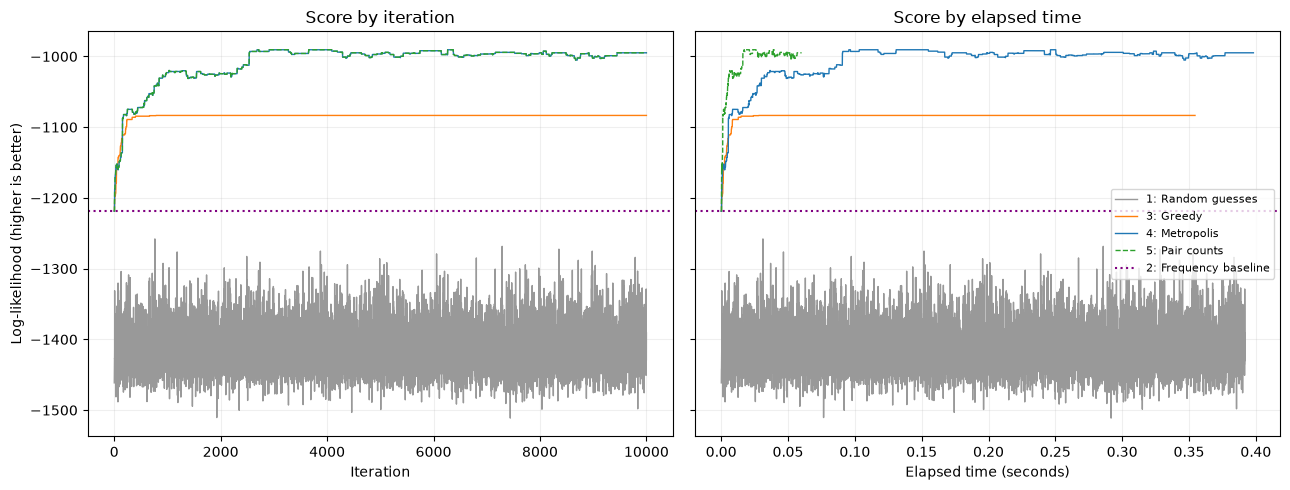

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

runs = [
    ("1: Random guesses", history1, "0.6", "-"),
    ("3: Greedy", history3, "tab:orange", "-"),
    ("4: Metropolis", history4, "tab:blue", "-"),
    ("5: Pair counts", history5, "tab:green", "--"),
]

for label, history, color, style in runs:
    steps = [row[0] for row in history]
    seconds = [row[1] for row in history]
    scores = [row[2] for row in history]

    axes[0].plot(steps, scores, style, color=color, label=label, linewidth=1)
    axes[1].plot(seconds, scores, style, color=color, label=label, linewidth=1)

for ax in axes:
    # Stage 2 makes one guess, so its score is a horizontal reference line.
    ax.axhline(score2, color="purple", linestyle=":", label="2: Frequency baseline")
    ax.grid(alpha=0.2)

axes[0].set(
    xlabel="Iteration",
    ylabel="Log-likelihood (higher is better)",
    title="Score by iteration"
)
axes[1].set(
    xlabel="Elapsed time (seconds)",
    title="Score by elapsed time"
)
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig("experiment2_search_progress.png", dpi=200, bbox_inches="tight")
plt.show()